# Discrete Maps: from One Map to a Network

**Code:** [Open in Colab](https://colab.research.google.com/github/hy20577/complex-network-dynamics/blob/main/mkdoc_material/docs/tutorials/03_discrete_maps.ipynb) · [Download the notebook](https://hy20577.github.io/complex-network-dynamics/tutorials/03_discrete_maps/03_discrete_maps.ipynb) · [View on GitHub](https://github.com/hy20577/complex-network-dynamics/blob/main/mkdoc_material/docs/tutorials/03_discrete_maps.ipynb)

The simplest dynamical systems in the library are discrete maps: a rule $x_{n+1} = f(x_n)$ that
is applied again and again. In this guide we study the two maps used in
[Yıldırım & Antonopoulos (2024)](https://doi.org/10.1016/j.chaos.2024.115554) [[1](#ref-1)], the logistic
map and the circle map, first on their own and then coupled on a network, following Chapter 3
(Sections 3.1 to 3.3) of the [PhD thesis](https://repository.essex.ac.uk/39296/) [[2](#ref-2)]. The data
generated here are the ones from which the networks are inferred in the later tutorials.

You will learn:

1. how the logistic map goes from a fixed point to chaos as its parameter $r$ grows, and how to
   draw its bifurcation diagram;
2. what a Lyapunov exponent is, and how it tells chaotic from regular behaviour;
3. how the circle map behaves, and why we use $r = 0.35$;
4. how to couple maps on a network with `simulate_discrete_models`, and how to compute their
   Lyapunov spectrum.

In [1]:
try:
    import complex_network_dynamics as cnd
except ImportError:  # e.g. on Google Colab: install the library from GitHub
    %pip install -q git+https://github.com/hy20577/complex-network-dynamics.git
    import complex_network_dynamics as cnd

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

rng = np.random.default_rng(0)  # fixed seed, so the results are the same on every run

## 1. The Logistic Map

The logistic map, popularised by Robert May in 1976 [[3](#ref-3)], is a model of a population that grows
when it is small and shrinks when it is crowded,

$$
x_{n+1} = r\, x_n (1 - x_n),
$$

where $x_n \in [0, 1]$ is the population at iteration $n$, which plays the role of discrete time,
and $r \in [0, 4]$ is the growth rate. This is Eq. (14) of the paper and Eq. (3.6) of the thesis,
and `cnd.logistic` in the library.

The sequence $x_0, x_1, x_2, \dots$ is called a trajectory or orbit. Its long-term behaviour
depends on $r$:

- for $r = 2$ the trajectory ends at $x = 0.5$, a **fixed point**, namely a point that satisfies
  $f(x) = x$. Indeed, $2x(1 - x) = x$ gives $x = 0$ or $x = 0.5$;
- for $r = 3.4$ it jumps between two points for ever (a period-2 orbit);
- for $r = 4$ it never repeats itself: the map is chaotic.

We plot the three cases below, starting from the same initial condition $x_0 = 0.4$.

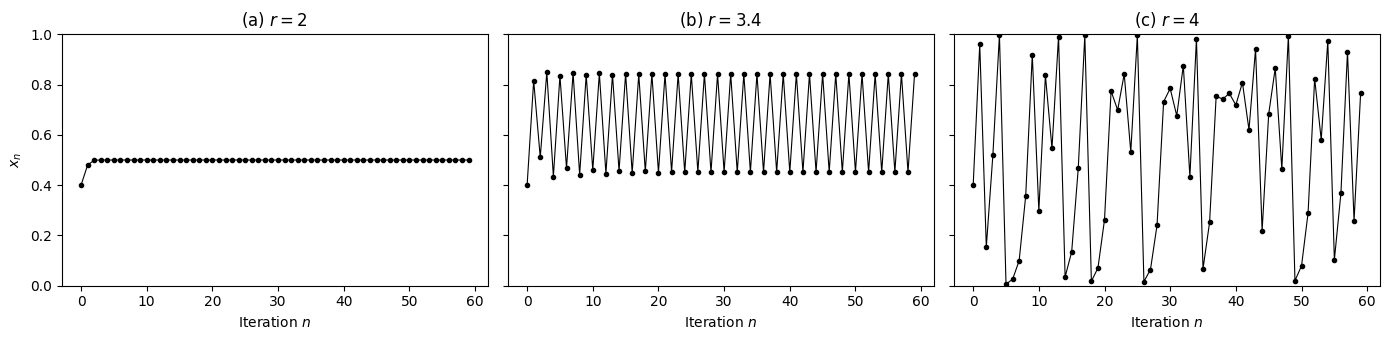

In [2]:
n_steps = 60
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)

for ax, letter, r in zip(axes, "abc", [2, 3.4, 4]):
    x = np.empty(n_steps)
    x[0] = 0.4
    for n in range(1, n_steps):
        x[n] = cnd.logistic(x[n - 1], r=r)
    ax.plot(x, "k.-", linewidth=0.8)
    ax.set_title(f"({letter}) $r = {r}$")
    ax.set_xlabel("Iteration $n$")

axes[0].set_ylabel("$x_n$")
axes[0].set_ylim(0, 1)
plt.tight_layout()
plt.show()

**Figure 1:** The first 60 iterations of the logistic map from $x_0 = 0.4$ for (a) $r = 2$, where the orbit converges to the fixed point $x^* = 1 - 1/r = 0.5$, (b) $r = 3.4$, where it settles on a periodic orbit of period 2, alternating between about 0.45 and 0.84, and (c) $r = 4$, where it never repeats itself and keeps visiting the whole interval $[0, 1]$.

## 2. Bifurcation Diagram of the Logistic Map

To see all the values of $r$ at once, we iterate the map for each $r$, discard the first
iterations (the transient) and plot the points the trajectory visits afterwards. This is the
bifurcation diagram (Fig. 3.5 of the thesis).

For $r \in (1, 3)$, the trajectories converge to a fixed point. As $r$ increases from 3, one
observes period 2, period 4, period 8, and so on: the period doubles again and again, and the
doublings come closer and closer to each other. If the $n$th doubling occurs at $r = r_n$, the
ratio $(r_n - r_{n-1}) / (r_{n+1} - r_n)$ tends to the Feigenbaum constant, $\delta \approx 4.6692$,
which is the same for a large family of maps. The orbits become chaotic around $r = 3.57$. An
emergence of period-3 behaviour is observed around $r = 3.83$, followed by a rapid return to
irregularity.

`cnd.logistic` accepts arrays, so we iterate all the values of $r$ together.

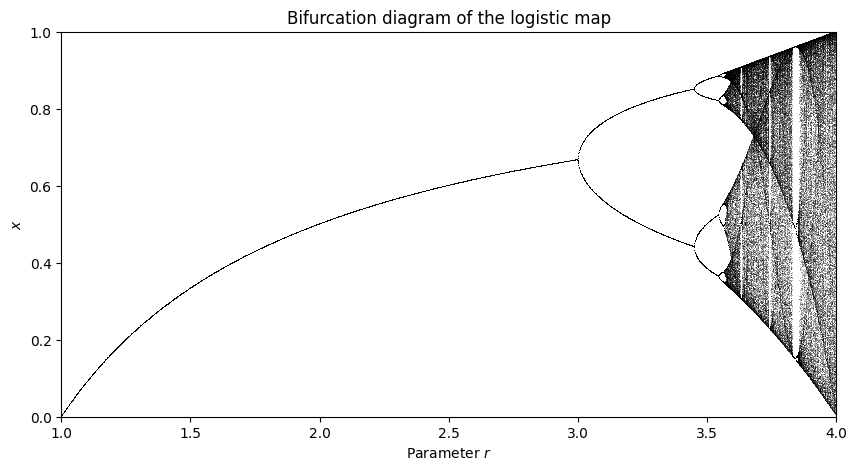

In [3]:
def bifurcation(f, r_values, n_transient=1000, n_keep=300, **params):
    """Points visited by x -> f(x, r) after the transient, for every r at once.

    Returns an array of shape (n_keep, len(r_values)).
    """
    x = np.full(len(r_values), 0.4)
    for _ in range(n_transient):
        x = f(x, r=r_values, **params)
    orbit = np.empty((n_keep, len(r_values)))
    for n in range(n_keep):
        x = f(x, r=r_values, **params)
        orbit[n] = x
    return orbit


r_logistic = np.linspace(1, 4, 2000)
orbit_logistic = bifurcation(cnd.logistic, r_logistic)

plt.figure(figsize=(10, 5))
plt.plot(r_logistic, orbit_logistic.T, "k,", alpha=0.3, rasterized=True)
plt.xlim(1, 4)
plt.ylim(0, 1)
plt.xlabel("Parameter $r$")
plt.ylabel("$x$")
plt.title("Bifurcation diagram of the logistic map")
plt.show()

**Figure 2:** Bifurcation diagram of the logistic map: for each of 2000 values of $r$ in $[1, 4]$, the 300 points visited by the orbit from $x_0 = 0.4$ after a transient of 1000 iterations. A single point for a value of $r$ means a fixed point, a few points a periodic orbit, and a vertical band of points a chaotic orbit.

## 3. Lyapunov Exponent of a Map

The bifurcation diagram shows where the map looks irregular; the Lyapunov exponent measures it.
Two trajectories that start a small distance $\epsilon$ apart are, after one iteration, about
$|f'(x)|\,\epsilon$ apart. The Lyapunov exponent is the average of the logarithm of this growth
rate along the trajectory (Section 3.2.1 of the thesis; see also [[4](#ref-4)]),

$$
\lambda = \lim_{k \to \infty} \frac{1}{k} \sum_{n=1}^{k} \log |f'(x_n)|.
$$

If $\lambda > 0$, nearby trajectories separate exponentially fast, as $\epsilon\, e^{\lambda n}$,
so the system is sensitive to its initial condition, which is the signature of chaos. If
$\lambda < 0$, they approach each other and the behaviour is regular (a fixed point or a
periodic orbit).

For the logistic map, $f'(x) = r(1 - 2x)$, which is `cnd.df_logistic`. For $r = 4$ the exact
value is known, $\lambda = \log 2 \approx 0.693$. Below, we compute $\lambda$ for every $r$ and
plot it over the bifurcation diagram, as in Fig. 3.9(a) of the thesis.

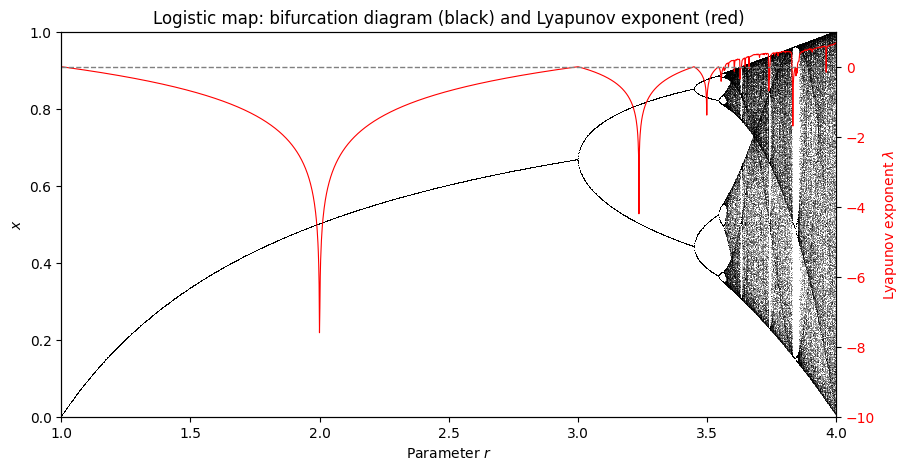

Lyapunov exponent at r = 4: 0.6936   (exact: log 2 = 0.6931)


In [4]:
def lyapunov_exponent(f, df, r_values, n_transient=1000, n_average=5000, **params):
    """Lyapunov exponent of x -> f(x, r): the average of log|f'(x)| along the orbit, for every r at once."""
    x = np.full(len(r_values), 0.4)
    for _ in range(n_transient):
        x = f(x, r=r_values, **params)
    total = np.zeros(len(r_values))
    with np.errstate(divide="ignore"):  # log(0) = -inf when the orbit sits exactly where f' = 0
        for _ in range(n_average):
            total += np.log(np.abs(df(x, r=r_values, **params)))
            x = f(x, r=r_values, **params)
    return total / n_average


def plot_bifurcation_and_exponent(r_values, orbit, exponent, title, exponent_range):
    fig, ax1 = plt.subplots(figsize=(10, 5))
    ax1.plot(r_values, orbit.T, "k,", alpha=0.3, rasterized=True)
    ax1.set_xlim(r_values[0], r_values[-1])
    ax1.set_ylim(0, 1)
    ax1.set_xlabel("Parameter $r$")
    ax1.set_ylabel("$x$")

    ax2 = ax1.twinx()
    ax2.plot(r_values, exponent, color="red", linewidth=0.8)
    ax2.axhline(0, color="gray", linestyle="--", linewidth=1)
    ax2.set_ylim(exponent_range)
    ax2.set_ylabel(r"Lyapunov exponent $\lambda$", color="red")
    ax2.tick_params(axis="y", labelcolor="red")
    plt.title(title)
    plt.show()


lambda_logistic = lyapunov_exponent(cnd.logistic, cnd.df_logistic, r_logistic)
plot_bifurcation_and_exponent(r_logistic, orbit_logistic, lambda_logistic,
                              "Logistic map: bifurcation diagram (black) and Lyapunov exponent (red)", (-10, 1))

print(f"Lyapunov exponent at r = 4: {lambda_logistic[-1]:.4f}   (exact: log 2 = {np.log(2):.4f})")

**Figure 3:** The bifurcation diagram of the logistic map of Fig. 2 (black, left axis) and its Lyapunov exponent $\lambda$ (red, right axis) for the same values of $r$, averaged over 5000 iterations after a transient of 1000. The dashed grey line marks $\lambda = 0$. The axis of $\lambda$ goes down to $-10$, so that the deep dips at $r = 2$ and $r \approx 3.24$ can be seen.

The red curve is negative wherever the black points form a few lines (fixed points and periodic
orbits), touches zero at every period doubling, and is positive where the black points fill
whole intervals. The dips inside the chaotic region are the periodic windows, such as the
period-3 window around $r = 3.83$. The two deepest dips, at $r = 2$ and $r = 1 + \sqrt{5} \approx 3.24$,
are superstable orbits: the fixed point ($r = 2$) or the period-2 orbit ($r \approx 3.24$) passes
through $x = 1/2$, where $f'(x) = 0$, so $\lambda \to -\infty$; the plot shows finite values only because
the exponent is averaged over a finite number of iterations on a grid of $r$ values.

The library computes the same quantity. `simulate_discrete_models` iterates maps on a network
and returns the trajectory together with the Lyapunov exponents; a single map is a network of
one node with no links.

In [5]:
one_node = np.zeros((1, 1))  # a single node with no links

trajectory, exponents = cnd.simulate_discrete_models(
    rng.random(1), cnd.logistic, cnd.df_logistic, one_node, t=10**5, alpha=0, r=4,
)
print("Trajectory shape:", trajectory.shape)
print(f"Lyapunov exponent at r = 4 from the library: {exponents[0]:.4f}")

Trajectory shape: (100000, 1)
Lyapunov exponent at r = 4 from the library: 0.6931


## 4. The Circle Map

The second map of the paper is the circle map (Eq. (15) of the paper, Eq. (3.12) of the thesis),

$$
x_{n+1} = x_n + r - \frac{K}{2\pi} \sin(2\pi x_n) \pmod 1,
$$

where $x_n \in [0, 1)$, $r \in [0, 1]$ is a parameter and $K = 6.9115$. In the library it is
`cnd.circle`, with the derivative $f'(x) = 1 - K\cos(2\pi x)$ in `cnd.df_circle`. We repeat the
same analysis, which gives Fig. 3.9(b) of the thesis.

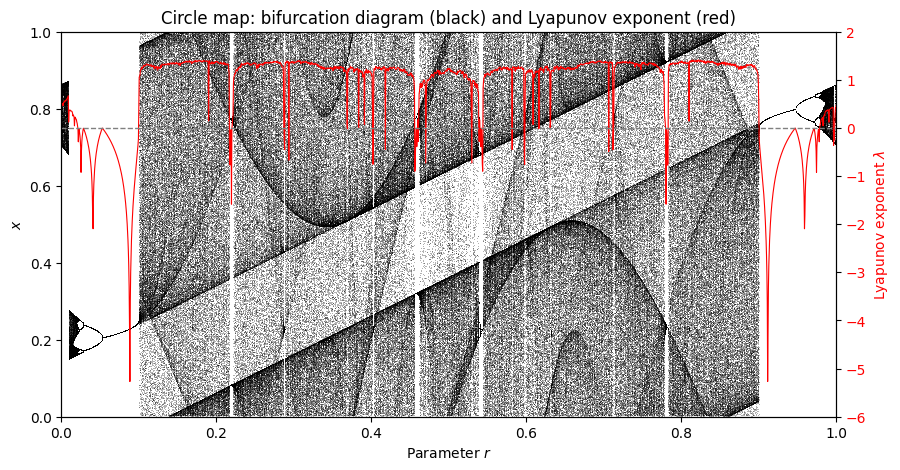

Lyapunov exponent at r = 0.350: 1.212


In [6]:
r_circle = np.linspace(0, 1, 2000)
orbit_circle = bifurcation(cnd.circle, r_circle)
lambda_circle = lyapunov_exponent(cnd.circle, cnd.df_circle, r_circle)

plot_bifurcation_and_exponent(r_circle, orbit_circle, lambda_circle,
                              "Circle map: bifurcation diagram (black) and Lyapunov exponent (red)", (-6, 2))

at_035 = np.argmin(np.abs(r_circle - 0.35))
print(f"Lyapunov exponent at r = {r_circle[at_035]:.3f}: {lambda_circle[at_035]:.3f}")

**Figure 4:** The bifurcation diagram of the circle map (black, left axis) and its Lyapunov exponent $\lambda$ (red, right axis) for 2000 values of $r$ in $[0, 1]$, with $K = 6.9115$, computed as for the logistic map in Fig. 3. The dashed grey line marks $\lambda = 0$. At $r = 0.35$, the value we use from now on, $\lambda \approx 1.21 > 0$, so the map is chaotic.

The circle map shows dynamics similar to those of the logistic map: intervals of $r$ with periodic
orbits, where $\lambda < 0$, alternate with chaotic ones, where $\lambda > 0$. For the system to
be chaotic, we choose $r = 0.35$ in all the computations that follow, which is the default of
`cnd.circle`.

## 5. Coupled Maps on a Network

So far every map evolved on its own. To generate data from a network, we place one map on every
node and let each node feel its neighbours (Eq. (13) of the paper, Eq. (3.13) of the thesis),

$$
x^{i}_{n+1} = (1 - \alpha)\, f(x^{i}_{n}, r) + \frac{\alpha}{k_i} \sum_{j=1}^{M} A_{ij}\, f(x^{j}_{n}, r),
$$

where $x^{i}_{n}$ is the $n$th iteration of node $i$, $M$ the number of nodes, $A$ the adjacency
matrix of the network, $k_i$ the degree of node $i$ and $\alpha \in [0, 1]$ the coupling strength.
For $\alpha = 0$ the nodes are independent, and as $\alpha$ grows each node follows the average
of its neighbours more and more.

The library ships with the two networks used in the thesis (Fig. 3.10): one with 12 nodes and
14 links, and one with 16 nodes and 26 links. We load them with `cnd.load_network`.

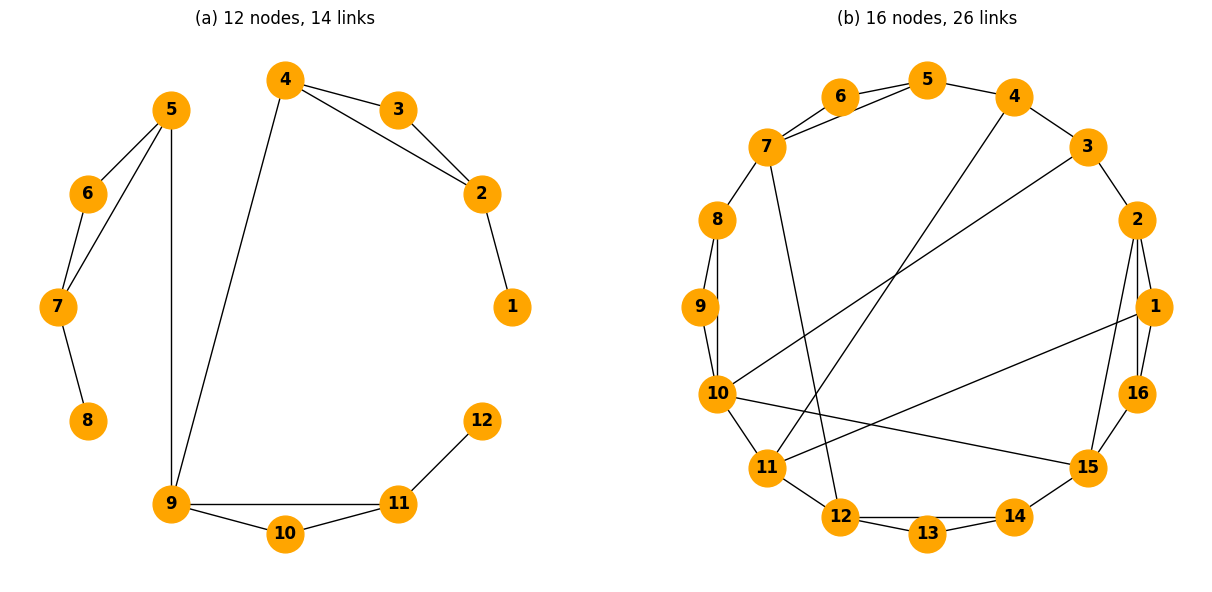

In [7]:
A12 = cnd.load_network("12nodes")
A16 = cnd.load_network("16nodes")

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, letter, A in zip(axes, "ab", [A12, A16]):
    G = nx.from_numpy_array(A)
    G = nx.relabel_nodes(G, lambda node: node + 1)  # number the nodes from 1, as in the thesis
    nx.draw(G, pos=nx.circular_layout(G), ax=ax, with_labels=True, node_color="orange", node_size=700,
            font_weight="bold", edge_color="black")
    ax.set_title(f"({letter}) {len(G)} nodes, {G.number_of_edges()} links")
    ax.set_aspect("equal")
plt.tight_layout()
plt.show()

**Figure 5:** The two networks of the library, loaded with `cnd.load_network` and drawn with the nodes on a circle: (a) the network of 12 nodes and 14 links and (b) the network of 16 nodes and 26 links, which are used in the paper and the thesis. The nodes are numbered from 1.

We now simulate 16 coupled logistic maps with $r = 4$ and $\alpha = 0.1$, and 16 coupled circle
maps with $r = 0.35$ and the same $\alpha$, from random initial conditions in $[0, 1]$. The first
$10^4$ iterations are discarded (`n_transient`), and the next $10^5$ are recorded (`t`). The
function returns the trajectory, with one column per node, and the Lyapunov exponents, which we
discuss in the next section.

In [8]:
M = A16.shape[0]
x0 = rng.random(M)
alpha = 0.1

traj_logistic, spectrum_logistic = cnd.simulate_discrete_models(
    x0, cnd.logistic, cnd.df_logistic, A16, t=10**5, alpha=alpha, n_transient=10**4, r=4,
)
traj_circle, spectrum_circle = cnd.simulate_discrete_models(
    x0, cnd.circle, cnd.df_circle, A16, t=10**5, alpha=alpha, n_transient=10**4, r=0.35, K=6.9115,
)
print("Shape of each trajectory (iterations, nodes):", traj_logistic.shape)

Shape of each trajectory (iterations, nodes): (100000, 16)


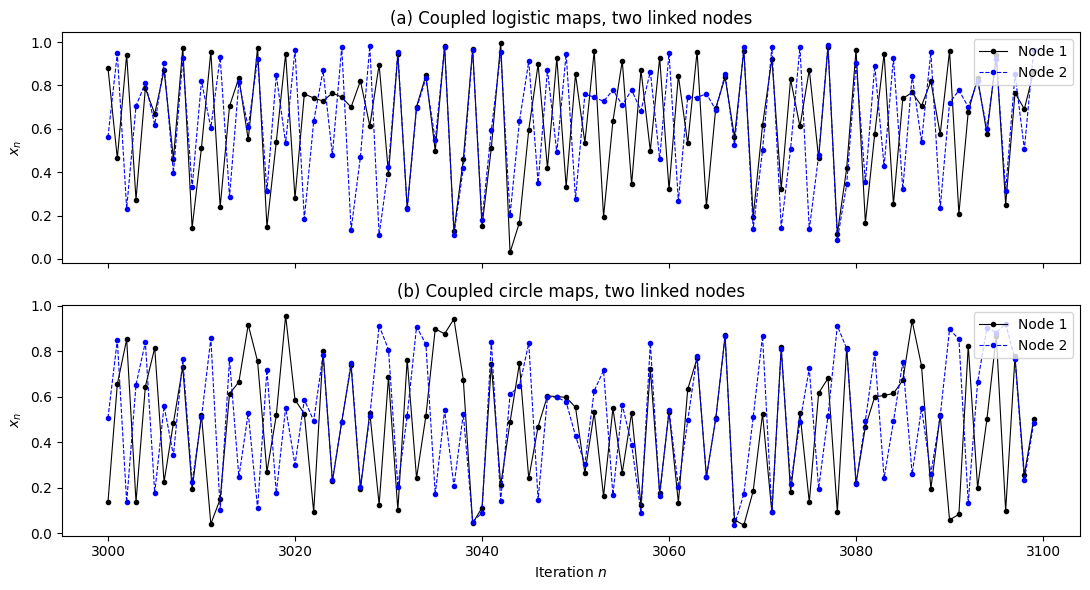

In [9]:
linked = np.argwhere(np.triu(A16))[0]  # the first linked pair of nodes
window = slice(3000, 3100)

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for ax, letter, traj, name in zip(axes, "ab", [traj_logistic, traj_circle], ["logistic", "circle"]):
    for node, style in zip(linked, ["k.-", "b.--"]):
        ax.plot(range(window.start, window.stop), traj[window, node], style, linewidth=0.8, label=f"Node {node + 1}")
    ax.set_ylabel("$x_n$")
    ax.set_title(f"({letter}) Coupled {name} maps, two linked nodes")
    ax.legend(loc="upper right")
axes[1].set_xlabel("Iteration $n$")
plt.tight_layout()
plt.show()

**Figure 6:** The trajectories of two linked nodes, nodes 1 and 2, of the 16-node network over 100 iterations (from iteration 3000 to 3099) for (a) the coupled logistic maps with $r = 4$ and (b) the coupled circle maps with $r = 0.35$, both with $\alpha = 0.1$. Node 1 is shown in black (solid) and node 2 in blue (dashed).

Although the two nodes are linked, their trajectories do not look alike: with $\alpha = 0.1$ the
coupling is weak and each node stays chaotic. This is what makes network inference difficult,
and why it needs the tools of the guides on
[correlation and mutual information](06_correlation_and_mutual_information.ipynb) and on
[MIR and APMSD](07_apmsd_network_inference.ipynb).

## 6. Lyapunov Spectrum of Coupled Maps

A system of $M$ coupled maps has $M$ Lyapunov exponents, $\lambda_1 \ge \lambda_2 \ge \dots \ge
\lambda_M$, called the Lyapunov spectrum: one average growth rate for each independent direction
in which a small perturbation can point (Section 3.2.2 of the thesis). To compute them, following
the algorithm of [[5](#ref-5), [6](#ref-6)],
`simulate_discrete_models` evolves $M$ orthonormal vectors with the Jacobian matrix of the
coupled system at every iteration, orthonormalises them again, and averages the logarithms of
their growth. Following the definition in [[4](#ref-4)], a bounded orbit is chaotic if it is not
asymptotically periodic, no exponent is exactly zero and at least one exponent is positive.

The table below lists the spectra of the 16 coupled logistic and circle maps with $\alpha = 0.1$
that we have just computed.

In [10]:
table = pd.DataFrame({
    "Logistic maps": np.round(spectrum_logistic, 2),
    "Circle maps": np.round(spectrum_circle, 2),
}, index=pd.RangeIndex(1, M + 1, name="Index"))
table

,Logistic maps,Circle maps
Index,,
1,0.45,1.21
2,0.44,1.18
3,0.44,1.15
4,0.43,1.12
5,0.42,1.09
6,0.42,1.06
7,0.41,1.03
8,0.40,1.00
9,0.39,0.97


All 16 exponents are positive in both cases, indicating that the dynamics is chaotic. Note that the largest
exponent of the coupled logistic maps, $\lambda_1 \approx 0.45$, is smaller than the $\log 2
\approx 0.69$ of a single map: the coupling averages the nodes and makes the system less chaotic.

## Summary

- The logistic map goes from a fixed point to chaos through period doublings as $r$ grows; the
  circle map shows similar dynamics. We use $r = 4$ and $r = 0.35$, respectively, where both are
  chaotic.
- The Lyapunov exponent is the average of $\log|f'(x_n)|$ along a trajectory. It is positive for
  chaotic behaviour and negative for regular behaviour.
- `cnd.simulate_discrete_models` couples any map on any network and returns the trajectory and
  the Lyapunov spectrum.

In the [next guide](04_integrating_odes.ipynb) we move from maps to systems of differential
equations.

## References

1. <a id="ref-1" name="ref-1"></a>H. Yıldırım and C. G. Antonopoulos, Network inference using mutual information rate,
   statistical tests and amplitude-phase modulated surrogate data, *Chaos, Solitons & Fractals*
   188, 115554 (2024). <https://doi.org/10.1016/j.chaos.2024.115554>
2. <a id="ref-2" name="ref-2"></a>H. Yıldırım, *Network Inference Using Information-theoretical Approaches, Statistical
   Hypothesis Tests, and The Amplitude-Phase Modulated Surrogate Data Method*, PhD thesis,
   University of Essex (2024), Chapter 3. <https://repository.essex.ac.uk/39296/>
3. <a id="ref-3" name="ref-3"></a>R. M. May, Simple mathematical models with very complicated dynamics, *Nature* 261, 459–467
   (1976).
4. <a id="ref-4" name="ref-4"></a>K. T. Alligood, T. D. Sauer and J. A. Yorke, *Chaos: An Introduction to Dynamical Systems*,
   Springer (1996).
5. <a id="ref-5" name="ref-5"></a>G. Benettin, L. Galgani, A. Giorgilli and J.-M. Strelcyn, Lyapunov characteristic exponents
   for smooth dynamical systems and for Hamiltonian systems; a method for computing all of them.
   Part 1: Theory, *Meccanica* 15, 9–20 (1980).
6. <a id="ref-6" name="ref-6"></a>G. Benettin, L. Galgani, A. Giorgilli and J.-M. Strelcyn, Lyapunov characteristic exponents
   for smooth dynamical systems and for Hamiltonian systems; a method for computing all of them.
   Part 2: Numerical application, *Meccanica* 15, 21–30 (1980).

References 3 to 6 are the ones cited in Chapter 3 of the thesis [2].